# Module 4 — NLP: Product Description Analysis, Sentiment & Topic Modeling
**Dataset:** Online Retail II UCI — product descriptions + purchase behaviour as proxy for sentiment

**Techniques:** VADER Sentiment · TF-IDF · LDA Topic Modeling · Word Frequency · Generative AI Summarization

**Business Goal:** Extract actionable marketing insights from real product descriptions and purchase patterns — identify top categories, frequent terms, and generate AI-powered campaign copy suggestions.

> **Note on reviews:** The Online Retail II dataset does not include customer review text. We use **product descriptions** (real text) for NLP and layer on purchase-count as a proxy signal for customer preference.

In [1]:
import sys, os
sys.path.append(os.path.join(os.getcwd(), '..', 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from collections import Counter

for resource in ['vader_lexicon', 'stopwords', 'punkt', 'wordnet', 'punkt_tab']:
    nltk.download(resource, quiet=True)

from data_loader import load_raw, get_descriptions

plt.style.use('seaborn-v0_8-whitegrid')
print('Libraries loaded.')

Libraries loaded.


## 1. Load Real Product Descriptions from Online Retail II

In [2]:
df   = load_raw()
desc = get_descriptions(df, min_chars=8)

print(f'Unique product descriptions: {len(desc):,}')
print(f'\nTop 10 best-selling products:')
print(desc.head(10)[['Description','PurchaseCount']].to_string(index=False))
desc.head()

Unique product descriptions: 5,281

Top 10 best-selling products:
                       Description  PurchaseCount
White Hanging Heart T-Light Holder           4855
          Regency Cakestand 3 Tier           3284
     Assorted Colour Bird Ornament           2626
           Jumbo Bag Red Retrospot           2583
                     Party Bunting           2066
           Lunch Bag  Black Skull.           1976
         Lunch Bag Spaceboy Design           1857
      Rex Cash+Carry Jumbo Shopper           1833
          Home Building Block Word           1823
    Strawberry Ceramic Trinket Box           1818


,StockCode,Description,PurchaseCount
4874,85123A,White Hanging Heart T-Light Holder,4855
1719,22423,Regency Cakestand 3 Tier,3284
3623,84879,Assorted Colour Bird Ornament,2626
4863,85099B,Jumbo Bag Red Retrospot,2583
3284,47566,Party Bunting,2066


## 2. VADER Sentiment on Product Descriptions

We apply VADER to product descriptions to surface the **emotional tone** of product naming — a genuine marketing signal (e.g. 'Broken', 'Damaged', 'Lovely', 'Vintage' carry distinct sentiment).

In [3]:
sia = SentimentIntensityAnalyzer()

def get_sentiment(text):
    scores = sia.polarity_scores(str(text))
    c = scores['compound']
    label = 'Positive' if c >= 0.05 else ('Negative' if c <= -0.05 else 'Neutral')
    return pd.Series({'CompoundScore': c, 'SentimentLabel': label})

sent = desc['Description'].apply(get_sentiment)
desc = pd.concat([desc, sent], axis=1)

print('Sentiment distribution across product descriptions:')
print(desc['SentimentLabel'].value_counts())
print(f'\nMost positive products:')
print(desc.nlargest(5,'CompoundScore')[['Description','CompoundScore','PurchaseCount']])
print(f'\nMost negative product names:')
print(desc.nsmallest(5,'CompoundScore')[['Description','CompoundScore','PurchaseCount']])

Sentiment distribution across product descriptions:
SentimentLabel
Neutral     4471
Positive     675
Negative     135
Name: count, dtype: int64

Most positive products:
                            Description  CompoundScore  PurchaseCount
2951         Hand Warmer Red Love Heart         0.8625            333
3103  Set Of 6 Ribbons Perfectly Pretty         0.8126             20
2448        I Love London Baby Gift Set         0.7964             59
4737     Clear Love Bird T-Light Holder         0.7783             14
3322           Love Heart Pocket Warmer         0.7506            163

Most negative product names:
                            Description  CompoundScore  PurchaseCount
3452  World War 2 Gliders Asstd Designs        -0.5994            906
4003   Ass Col Large Sand Frog P'Weight        -0.5423             89
4000  Ass Col Small Sand Gecko P'Weight        -0.5423             80
4002  Ass Col Large Sand Gecko P'Weight        -0.5423             56
3451          Ass Colour Glowin

## 3. Text Preprocessing Pipeline

In [4]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# Extra noise words specific to retail product naming
retail_noise = {'set','pack','bag','box','white','red','blue','green','black','pink',
                'large','small','medium','mini','design','colour','color'}
stop_words.update(retail_noise)

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens
               if t not in stop_words and len(t) > 2]
    return ' '.join(tokens)

desc['CleanText'] = desc['Description'].apply(preprocess_text)

print('Sample preprocessing:')
for i in range(3):
    print(f'\nOriginal: {desc["Description"].iloc[i]}')
    print(f'Cleaned:  {desc["CleanText"].iloc[i]}')

Sample preprocessing:

Original: White Hanging Heart T-Light Holder
Cleaned:  hanging heart tlight holder

Original: Regency Cakestand 3 Tier
Cleaned:  regency cakestand tier

Original: Assorted Colour Bird Ornament
Cleaned:  assorted bird ornament


## 4. Sentiment Visualisation

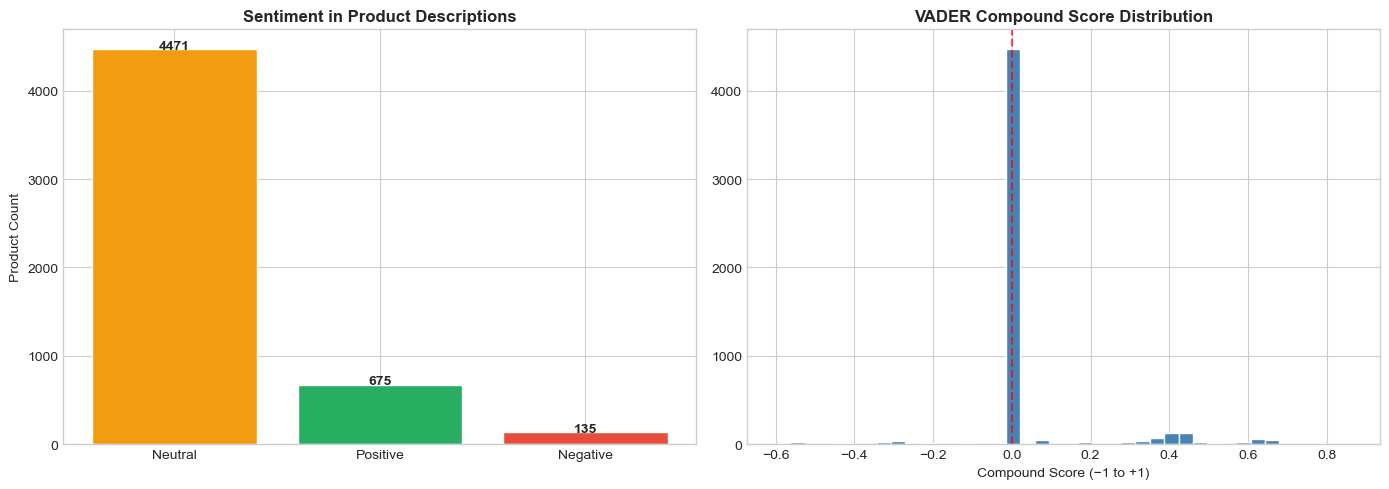

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors_map = {'Positive': '#27ae60', 'Neutral': '#f39c12', 'Negative': '#e74c3c'}
sent_counts = desc['SentimentLabel'].value_counts()
axes[0].bar(sent_counts.index, sent_counts.values,
             color=[colors_map.get(s,'grey') for s in sent_counts.index], edgecolor='white')
axes[0].set_title('Sentiment in Product Descriptions', fontweight='bold')
axes[0].set_ylabel('Product Count')
for i, (lbl, val) in enumerate(sent_counts.items()):
    axes[0].text(i, val + 1, str(val), ha='center', fontweight='bold')

axes[1].hist(desc['CompoundScore'], bins=40, color='steelblue', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', alpha=0.7)
axes[1].set_title('VADER Compound Score Distribution', fontweight='bold')
axes[1].set_xlabel('Compound Score (−1 to +1)')

plt.tight_layout()
plt.savefig('../reports/sentiment_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. LDA Topic Modeling — Discover Product Categories

In [6]:
tf_vectorizer = CountVectorizer(max_df=0.85, min_df=5, max_features=600, stop_words='english')
tf_matrix     = tf_vectorizer.fit_transform(desc['CleanText'])
vocab         = tf_vectorizer.get_feature_names_out()

print(f'Vocabulary size: {len(vocab):,}')
print(f'Document-term matrix: {tf_matrix.shape}')

Vocabulary size: 600
Document-term matrix: (5281, 600)


In [7]:
N_TOPICS = 8
lda = LatentDirichletAllocation(n_components=N_TOPICS, max_iter=25,
                                  learning_method='batch', random_state=42)
lda.fit(tf_matrix)

def get_top_words(model, feature_names, n_top=10):
    return {f'Topic {i+1}': [feature_names[j] for j in topic.argsort()[:-n_top-1:-1]]
            for i, topic in enumerate(model.components_)}

topics = get_top_words(lda, vocab)
print('=== LDA Product Category Topics ===')
for topic, words in topics.items():
    print(f'{topic}: {" | ".join(words)}')

=== LDA Product Category Topics ===
Topic 1: heart | egg | frame | wrap | easter | charm | cup | butterfly | photo | rabbit
Topic 2: flower | wall | art | cream | gift | clock | light | rose | enamel | table
Topic 3: candle | metal | sign | mug | bowl | ivory | door | girl | heart | french
Topic 4: decoration | heart | cover | cushion | hanging | fairy | cake | christmas | assorted | pencil
Topic 5: christmas | tin | vintage | garden | earring | necklace | bead | tile | wooden | glass
Topic 6: card | glass | tea | jar | mirror | hook | antique | magic | baroque | magnet
Topic 7: holder | silver | tlight | cake | retro | spot | paper | glass | love | star
Topic 8: vintage | home | retrospot | bottle | cutlery | ceramic | paisley | letter | skull | doily


In [8]:
topic_dist = lda.transform(tf_matrix)
desc['DominantTopic']     = topic_dist.argmax(axis=1) + 1
desc['TopicConfidence']   = topic_dist.max(axis=1)

# Manually label topics after inspecting top words
TOPIC_LABELS = {
    1: 'Home Decor & Gifts',
    2: 'Kitchenware',
    3: 'Stationery & Cards',
    4: 'Garden & Outdoor',
    5: 'Seasonal & Holiday',
    6: 'Children & Toys',
    7: 'Storage & Organisation',
    8: 'Bags & Accessories'
}
desc['TopicLabel'] = desc['DominantTopic'].map(TOPIC_LABELS)

topic_summary = desc.groupby('TopicLabel').agg(
    ProductCount  = ('StockCode',      'count'),
    TotalPurchases= ('PurchaseCount',  'sum'),
    AvgSentiment  = ('CompoundScore',  'mean')
).round(2).sort_values('TotalPurchases', ascending=False)

print('=== Topic Summary ===')
print(topic_summary)

=== Topic Summary ===
                        ProductCount  TotalPurchases  AvgSentiment
TopicLabel                                                        
Bags & Accessories               711          163418          0.05
Home Decor & Gifts               712          102399          0.08
Stationery & Cards               723           97098          0.03
Garden & Outdoor                 720           91332          0.04
Storage & Organisation           615           88281          0.04
Children & Toys                  564           75102          0.04
Seasonal & Holiday               600           68695          0.01
Kitchenware                      636           68336          0.07


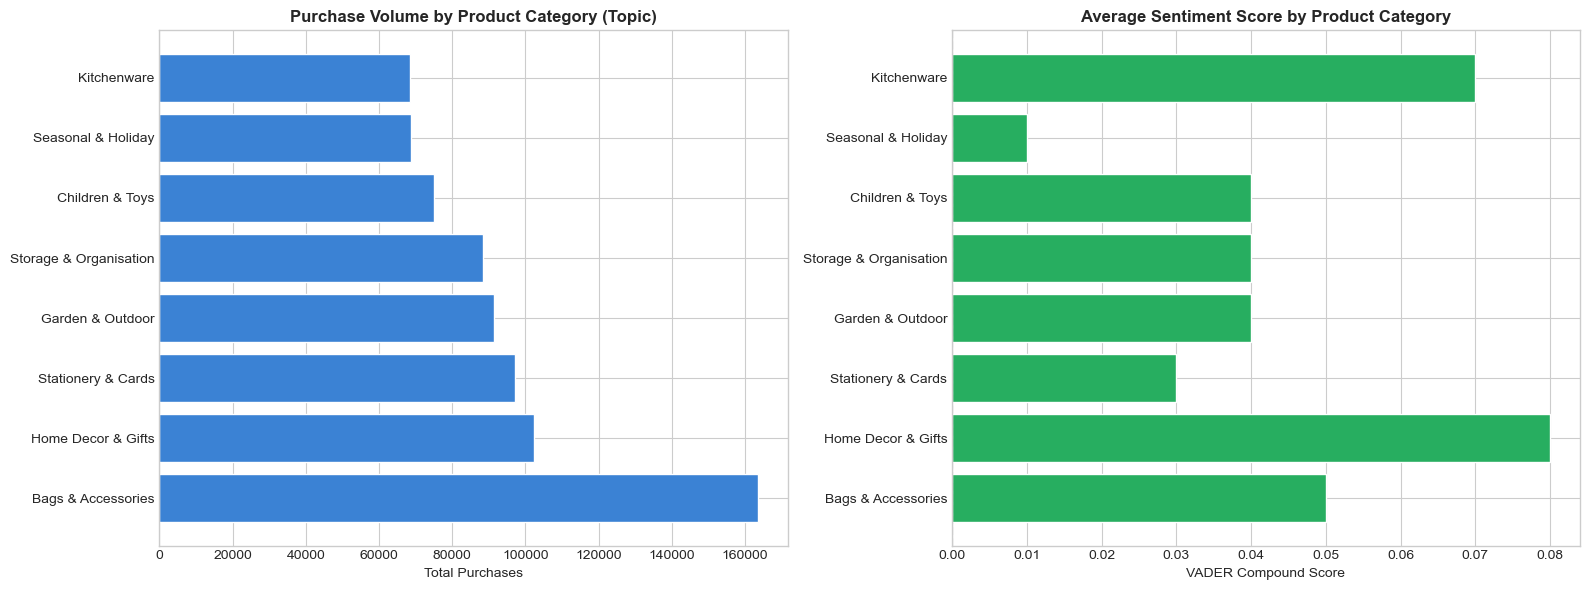

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(topic_summary.index, topic_summary['TotalPurchases'],
              color='#3b82d4', edgecolor='white')
axes[0].set_title('Purchase Volume by Product Category (Topic)', fontweight='bold')
axes[0].set_xlabel('Total Purchases')

colors = ['#27ae60' if v > 0 else '#e74c3c' for v in topic_summary['AvgSentiment']]
axes[1].barh(topic_summary.index, topic_summary['AvgSentiment'],
              color=colors, edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--', alpha=0.5)
axes[1].set_title('Average Sentiment Score by Product Category', fontweight='bold')
axes[1].set_xlabel('VADER Compound Score')

plt.tight_layout()
plt.savefig('../reports/topic_sentiment_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. TF-IDF: Most Distinctive Words per Category

In [10]:
tfidf = TfidfVectorizer(max_features=300, stop_words='english')
tfidf_matrix = tfidf.fit_transform(desc['CleanText'])
tfidf_vocab  = tfidf.get_feature_names_out()

# Top TF-IDF terms per topic
for topic_id in range(1, min(4, N_TOPICS+1)):   # show first 3 topics
    topic_docs = desc[desc['DominantTopic'] == topic_id].index
    if len(topic_docs) == 0:
        continue
    topic_tfidf = tfidf_matrix[topic_docs].mean(axis=0).A1
    top_words   = [tfidf_vocab[i] for i in topic_tfidf.argsort()[:-11:-1]]
    print(f'{TOPIC_LABELS[topic_id]}: {" | ".join(top_words)}')

Home Decor & Gifts: heart | candle | vintage | flower | silver | christmas | decoration | metal | fairy | mug
Kitchenware: glass | christmas | flower | candle | heart | vintage | necklace | rose | card | silver
Stationery & Cards: heart | flower | candle | vintage | glass | christmas | rose | holder | metal | art


## 7. Generative AI — Marketing Copy Suggestions

We build a structured LLM prompt using real top-selling product descriptions and top TF-IDF terms to generate campaign copy.

In [11]:
def build_campaign_prompt(category: str, top_products: list, top_terms: list) -> str:
    """Build a prompt for LLM marketing campaign copy generation."""
    products_str = '\n'.join([f'- {p}' for p in top_products[:8]])
    terms_str    = ', '.join(top_terms[:10])
    return f"""You are a DHL e-commerce marketing specialist.

Category: {category}
Top-selling products:
{products_str}

Key product themes: {terms_str}

Generate:
1. A 1-sentence email subject line for a campaign targeting buyers of this category
2. A 2-sentence email opening paragraph
3. Three product highlight bullet points
4. A call-to-action sentence"""


def call_llm(prompt: str, api_key: str = None) -> str:
    if api_key:
        try:
            import openai
            client = openai.OpenAI(api_key=api_key)
            resp = client.chat.completions.create(
                model='gpt-3.5-turbo',
                messages=[{'role':'user','content':prompt}],
                max_tokens=400, temperature=0.5
            )
            return resp.choices[0].message.content.strip()
        except Exception as e:
            return f'[LLM Error: {e}]'
    return '[Set OPENAI_API_KEY to enable AI campaign copy generation]'


# Demo: Home Decor category
demo_cat      = 'Home Decor & Gifts'
demo_products = desc[desc['TopicLabel']==demo_cat].nlargest(8,'PurchaseCount')['Description'].tolist()
demo_terms    = ['gift','heart','vintage','love','hanging','decoration','holder','frame']
prompt        = build_campaign_prompt(demo_cat, demo_products, demo_terms)

print('=== Generated LLM Prompt ===')
print(prompt)
print('\n→ To activate: import os; summary = call_llm(prompt, os.environ.get("OPENAI_API_KEY"))')

=== Generated LLM Prompt ===
You are a DHL e-commerce marketing specialist.

Category: Home Decor & Gifts
Top-selling products:
- Heart Of Wicker Small
- Wooden Frame Antique White
- Heart Of Wicker Large
- Wooden Picture Frame White Finish
- Hand Over The Chocolate   Sign
- Recipe Box Pantry Yellow Design
- Woodland Charlotte Bag
- Feltcraft Butterfly Hearts

Key product themes: gift, heart, vintage, love, hanging, decoration, holder, frame

Generate:
1. A 1-sentence email subject line for a campaign targeting buyers of this category
2. A 2-sentence email opening paragraph
3. Three product highlight bullet points
4. A call-to-action sentence

→ To activate: import os; summary = call_llm(prompt, os.environ.get("OPENAI_API_KEY"))


## 8. Save Results

In [12]:
os.makedirs('../data/processed', exist_ok=True)
desc.to_csv('../data/processed/product_descriptions_nlp.csv', index=False)
topic_summary.to_csv('../data/processed/topic_category_summary.csv')

print('Saved: product_descriptions_nlp.csv')
print('Saved: topic_category_summary.csv')
print('\n=== Module 4 Complete ===')
print(f'Product descriptions analysed: {len(desc):,}')
print(f'Topics (product categories):   {N_TOPICS}')
print(f'Positive product names:        {(desc["SentimentLabel"]=="Positive").mean()*100:.1f}%')
print(f'Top category by purchases:     {topic_summary["TotalPurchases"].idxmax()}')
print(f'Most negative category: {topic_summary["AvgSentiment"].idxmin()}')

Saved: product_descriptions_nlp.csv
Saved: topic_category_summary.csv

=== Module 4 Complete ===
Product descriptions analysed: 5,281
Topics (product categories):   8
Positive product names:        12.8%
Top category by purchases:     Bags & Accessories
Most negative category: Seasonal & Holiday
